<a href="https://colab.research.google.com/github/Souha2003/Brain-Tumor-MRI-/blob/main/TP4-SouhaNada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **importe les bibliothèques et vérifie que le GPU est actif texte en gras**

In [ ]:
import os, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)
print("GPU :", tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# **télécharger le dataset**

In [ ]:
import kagglehub
path = kagglehub.dataset_download("obulisainaren/retinal-oct-c8")
print("Téléchargé dans :", path)

Using Colab cache for faster access to the 'retinal-oct-c8' dataset.
Téléchargé dans : /kaggle/input/retinal-oct-c8


# **l'organisation des dossiers**

In [ ]:
for root, dirs, files in os.walk(path):
    depth = root.count(os.sep) - path.count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(root), f"({len(files)} fichiers)")

retinal-oct-c8 (1 fichiers)
  RetinalOCT_Dataset (0 fichiers)
    RetinalOCT_Dataset (0 fichiers)



# **montrer les dossiers plus bas, jusqu'aux classes.**



In [ ]:
for root, dirs, files in os.walk(path):
    depth = root.count(os.sep) - path.count(os.sep)
    if depth <= 4:
        print("  " * depth + os.path.basename(root), f"({len(files)} fichiers)")

retinal-oct-c8 (1 fichiers)
  RetinalOCT_Dataset (0 fichiers)
    RetinalOCT_Dataset (0 fichiers)
      val (0 fichiers)
        DR (350 fichiers)
        AMD (350 fichiers)
        CSR (350 fichiers)
        DRUSEN (350 fichiers)
        CNV (350 fichiers)
        NORMAL (350 fichiers)
        MH (350 fichiers)
        DME (350 fichiers)
      test (0 fichiers)
        DR (350 fichiers)
        AMD (350 fichiers)
        CSR (350 fichiers)
        DRUSEN (350 fichiers)
        CNV (350 fichiers)
        NORMAL (350 fichiers)
        MH (350 fichiers)
        DME (350 fichiers)
      train (0 fichiers)
        DR (2300 fichiers)
        AMD (2300 fichiers)
        CSR (2300 fichiers)
        DRUSEN (2300 fichiers)
        CNV (2300 fichiers)
        NORMAL (2300 fichiers)
        MH (2300 fichiers)
        DME (2300 fichiers)


Split	Images par classe	Total (8 classes)
train	2 300	18 400
val	350	2 800
test	350	2 800

# **définir les chemins et regarder les images**
# Cellule A : enregistrer les chemins

In [ ]:
DATA_DIR = os.path.join(path, "RetinalOCT_Dataset", "RetinalOCT_Dataset")
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "val")
TEST_DIR  = os.path.join(DATA_DIR, "test")

class_names = sorted(os.listdir(TRAIN_DIR))
print("Classes :", class_names)
print("Nombre de classes :", len(class_names))

Classes : ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
Nombre de classes : 8


afficher 4 images de chaque classe

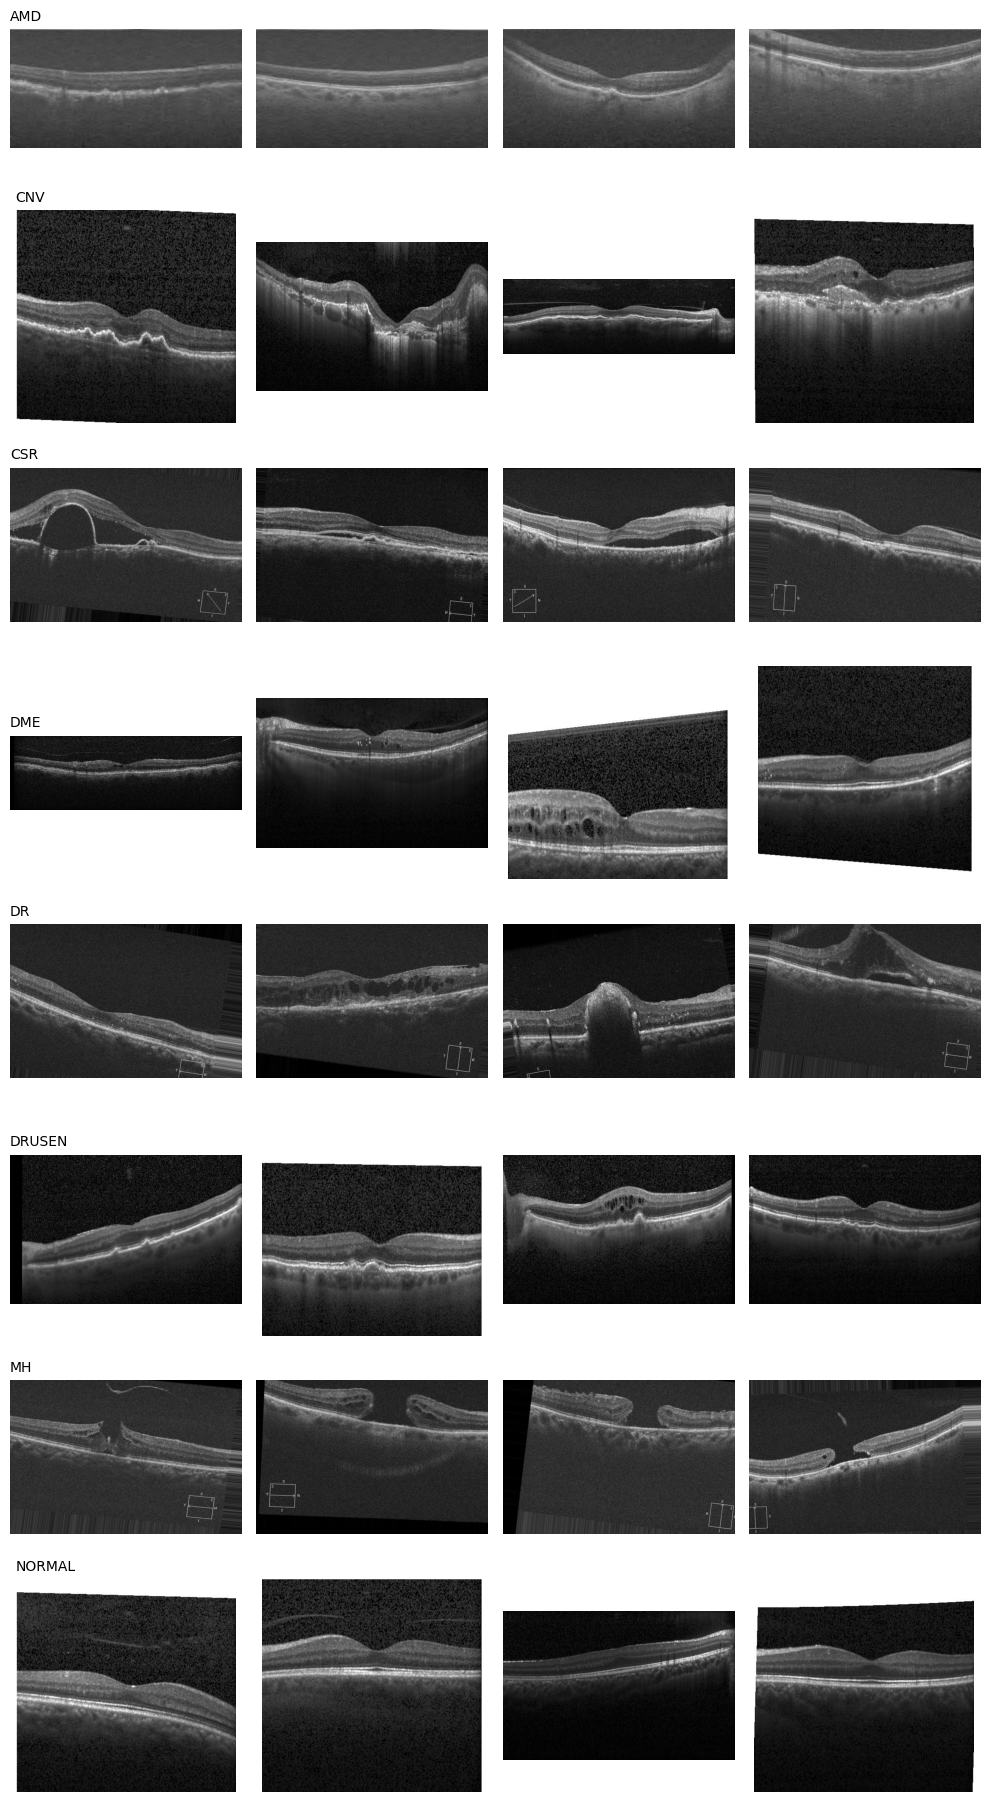

Tailles et modes des images : {((512, 496), 'L'), ((1000, 512), 'RGB'), ((1536, 496), 'L'), ((750, 500), 'RGB'), ((879, 586), 'RGB'), ((768, 496), 'L'), ((512, 512), 'L')}


In [ ]:
from PIL import Image

fig, axes = plt.subplots(len(class_names), 4, figsize=(10, 2.3 * len(class_names)))
sizes = set()
for i, cls in enumerate(class_names):
    files = random.sample(os.listdir(os.path.join(TRAIN_DIR, cls)), 4)
    for j, f in enumerate(files):
        im = Image.open(os.path.join(TRAIN_DIR, cls, f))
        sizes.add((im.size, im.mode))
        axes[i, j].imshow(im, cmap="gray")
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, loc="left", fontsize=10)
plt.tight_layout()
plt.show()
print("Tailles et modes des images :", sizes)

Étape 4 : charger les images dans TensorFlow

On transforme les dossiers en datasets TensorFlow : Keras lit les images, les redimensionne, les convertit en RGB et les groupe en batches de 32. Le nom de chaque sous-dossier devient l'étiquette (AMD = 0, CNV = 1, etc.).

Étape 4 : charger les images dans TensorFlow

On transforme les dossiers en datasets TensorFlow : Keras lit les images, les redimensionne, les convertit en RGB et les groupe en batches de 32. Le nom de chaque sous-dossier devient l'étiquette (AMD = 0, CNV = 1, etc.).

Cellule A : créer les trois datasets

In [ ]:
IMG_SIZE = (224, 224)
BATCH = 32

def load(d, shuffle):
    return keras.utils.image_dataset_from_directory(
        d, image_size=IMG_SIZE, batch_size=BATCH,
        label_mode='int', color_mode='rgb', shuffle=shuffle, seed=42)

train_ds = load(TRAIN_DIR, shuffle=True)
val_ds   = load(VAL_DIR,   shuffle=False)
test_ds  = load(TEST_DIR,  shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 18400 files belonging to 8 classes.
Found 2800 files belonging to 8 classes.
Found 2800 files belonging to 8 classes.
['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']


Cellule B : inspecter un **batch**

Forme d'un batch d'images : (32, 224, 224, 3)
Forme des étiquettes      : (32,)
Pixels min / max          : 0.0 255.0


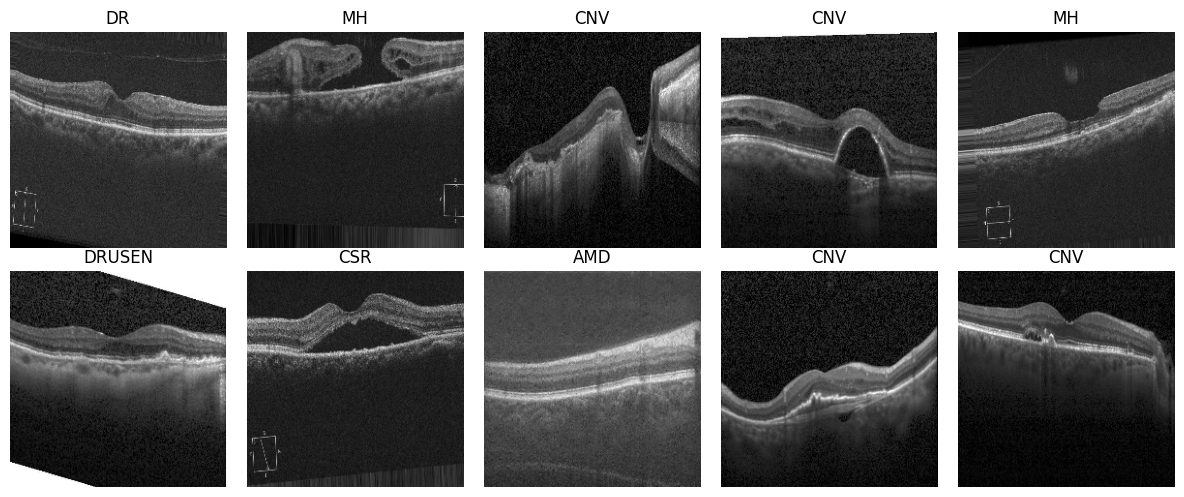

In [ ]:
images, labels = next(iter(train_ds))
print("Forme d'un batch d'images :", images.shape)
print("Forme des étiquettes      :", labels.shape)
print("Pixels min / max          :", images.numpy().min(), images.numpy().max())

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy().astype('uint8'))
    plt.title(class_names[int(labels[i])])
    plt.axis('off')
plt.tight_layout()
plt.show()

### Augmentation de données
Avec seulement 18 400 images pour 8 classes de pathologies, le modèle peut encore mémoriser. On génère des variantes **aléatoires** de chaque image (miroir horizontal, petite rotation, zoom) — uniquement pendant l'entraînement.

Les valeurs sont plus modérées que dans le TP4 (rotation 0.05 au lieu de 0.1) car sur une coupe OCT la **position des couches de la rétine** est un indice diagnostique : on évite les déformations trop fortes.

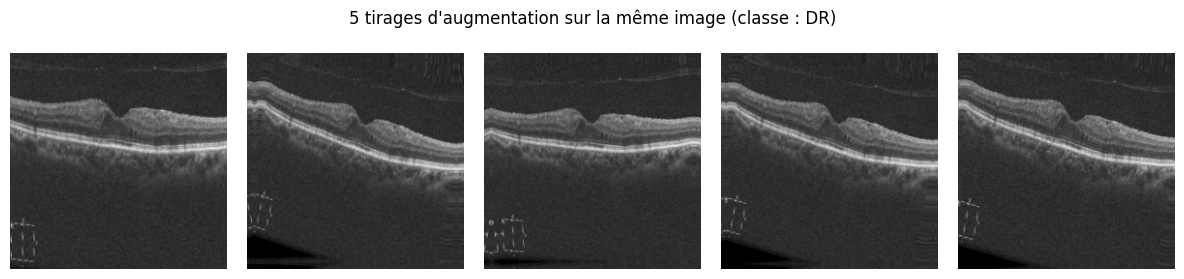

In [ ]:
# Définition de l'augmentation de données
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name='augmentation')

# Affichage de 5 tirages d'augmentation sur la première image du batch
img = images[0:1]
plt.figure(figsize=(12, 2.8))
for i in range(5):
    aug = data_augmentation(img, training=True)
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug[0].numpy().astype('uint8'))
    plt.axis('off')
plt.suptitle(f"5 tirages d'augmentation sur la même image (classe : {class_names[int(labels[0])]})")
plt.tight_layout()
plt.show()

## Partie 2 — Référence : un CNN entraîné *from scratch*
Même démarche que le TP4, mais sur des images OCT 224×224 avec **8 classes** : la dernière couche devient `Dense(8, activation='softmax')` et la loss `sparse_categorical_crossentropy` (étiquettes entières).

In [ ]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h.history['accuracy'], label='train'); ax[0].plot(h.history['val_accuracy'], label='val')
    ax[0].set_title(title + ' — accuracy'); ax[0].legend(); ax[0].set_xlabel('époque')
    ax[1].plot(h.history['loss'], label='train'); ax[1].plot(h.history['val_loss'], label='val')
    ax[1].set_title(title + ' — loss'); ax[1].legend(); ax[1].set_xlabel('époque')
    plt.tight_layout(); plt.show()

results = {}   # nom -> (test_acc, params entraînables, durée en s)

In [ ]:
scratch = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
], name='cnn_scratch')

scratch.compile(optimizer=keras.optimizers.Adam(1e-3),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
scratch.summary()

Model: "cnn_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,864 (944.78 KB)

 Trainable params: 241,864 (944.78 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS_SCRATCH = 15   # 18 400 images : chaque époque est ~9x plus longue que dans le TP4
t0 = time.time()
h_scratch = scratch.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_SCRATCH, verbose=2)
t_scratch = time.time() - t0
plot_history(h_scratch, 'CNN from scratch')
loss, acc = scratch.evaluate(test_ds, verbose=0)
results['CNN from scratch'] = (acc, sum(np.prod(w.shape) for w in scratch.trainable_weights), t_scratch)
print(f"Test accuracy : {acc:.3f}  |  durée : {t_scratch:.0f} s")

> ❓ **Question 3.** Quelle précision test obtenez-vous ? Comment évoluent les courbes train/val ? Selon vous, qu'est-ce qui limite ce modèle : l'architecture ou la quantité de données ?

✍️ *Votre réponse :*

**Précision test** : **[XX %]** *(à recopier depuis la sortie de la cellule d'entraînement)*.

**Courbes train/val** : *(à décrire d'après vos graphiques : la courbe train monte-t-elle plus vite que la val ? la loss val remonte-t-elle ? l'écart train/val est-il grand ?)*

**Ce qui limite le modèle** : à compléter selon vos courbes. Si l'écart train/val est important → surapprentissage. Attention, ici le contexte diffère du TP4 : on a **18 400 images** (et non 2 000), donc la quantité de données est moins critique ; en revanche les images OCT sont très différentes d'ImageNet, et les 8 classes se ressemblent (CNV, DME, DRUSEN, AMD…), ce qui rend la tâche plus fine que « chat vs chien ».

## Partie 3 — Transfer Learning : VGG16 comme extracteur de caractéristiques
**Idée** : VGG16 a appris sur **1,2 million d'images ImageNet** des filtres génériques : contours → textures → motifs → parties d'objets. On garde sa **base convolutive** (`include_top=False`), on la **gèle**, et on n'entraîne qu'une petite tête de classification.

> Remarque : ImageNet ne contient pas d'images médicales. Le transfert fonctionne quand même car les filtres de bas niveau (bords, textures) sont universels.

### 3.1 — Charger la base VGG16

In [ ]:
# Base convolutive de VGG16 pré-entraînée sur ImageNet, SANS la tête
conv_base = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=IMG_SIZE + (3,)
)

conv_base.summary()
print("Sortie de la base :", conv_base.output_shape)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

Sortie de la base : (None, 7, 7, 512)


### 3.2 — Extraction rapide (sans augmentation)
On fait passer **une seule fois** toutes les images dans VGG16 et on stocke les cartes de caractéristiques. On entraîne ensuite un petit classifieur dense dessus : très rapide.

⚠️ VGG16 attend ses entrées prétraitées comme pendant son entraînement : `keras.applications.vgg16.preprocess_input` (BGR + soustraction de la moyenne ImageNet).

In [ ]:
pre_vgg = keras.applications.vgg16.preprocess_input

def extract_features(base, preprocess, ds, pool=False):
    """Passe tout le dataset dans `base` et renvoie (caractéristiques, étiquettes).
    pool=True : moyenne spatiale (GlobalAveragePooling) faite à l'extraction pour économiser la RAM."""
    feats, labs = [], []
    for x, y in ds:
        f = base(preprocess(x), training=False)
        if pool:
            f = tf.reduce_mean(f, axis=[1, 2])
        feats.append(f.numpy())
        labs.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labs)

t0 = time.time()
Xtr, ytr = extract_features(conv_base, pre_vgg, train_ds)
Xva, yva = extract_features(conv_base, pre_vgg, val_ds)
Xte, yte = extract_features(conv_base, pre_vgg, test_ds)
t_extract = time.time() - t0

print("Xtr :", Xtr.shape, "| Xva :", Xva.shape, "| Xte :", Xte.shape)
print(f"Extraction : {t_extract:.0f} s")

Xtr : (18400, 7, 7, 512) | Xva : (2800, 7, 7, 512) | Xte : (2800, 7, 7, 512)
Extraction : 185 s


Epoch 1/20
575/575 - 8s - 14ms/step - accuracy: 0.5013 - loss: 1.7128 - val_accuracy: 0.7714 - val_loss: 0.6350
Epoch 2/20
575/575 - 4s - 6ms/step - accuracy: 0.7247 - loss: 0.7536 - val_accuracy: 0.8214 - val_loss: 0.4814
Epoch 3/20
575/575 - 3s - 5ms/step - accuracy: 0.7760 - loss: 0.6024 - val_accuracy: 0.8450 - val_loss: 0.4145
Epoch 4/20
575/575 - 3s - 5ms/step - accuracy: 0.8117 - loss: 0.5094 - val_accuracy: 0.8639 - val_loss: 0.3659
Epoch 5/20
575/575 - 6s - 10ms/step - accuracy: 0.8311 - loss: 0.4492 - val_accuracy: 0.8764 - val_loss: 0.3408
Epoch 6/20
575/575 - 3s - 5ms/step - accuracy: 0.8457 - loss: 0.4103 - val_accuracy: 0.8854 - val_loss: 0.3176
Epoch 7/20
575/575 - 3s - 5ms/step - accuracy: 0.8580 - loss: 0.3788 - val_accuracy: 0.8904 - val_loss: 0.3018
Epoch 8/20
575/575 - 3s - 5ms/step - accuracy: 0.8662 - loss: 0.3549 - val_accuracy: 0.8957 - val_loss: 0.2919
Epoch 9/20
575/575 - 3s - 5ms/step - accuracy: 0.8801 - loss: 0.3298 - val_accuracy: 0.9004 - val_loss: 0.2806

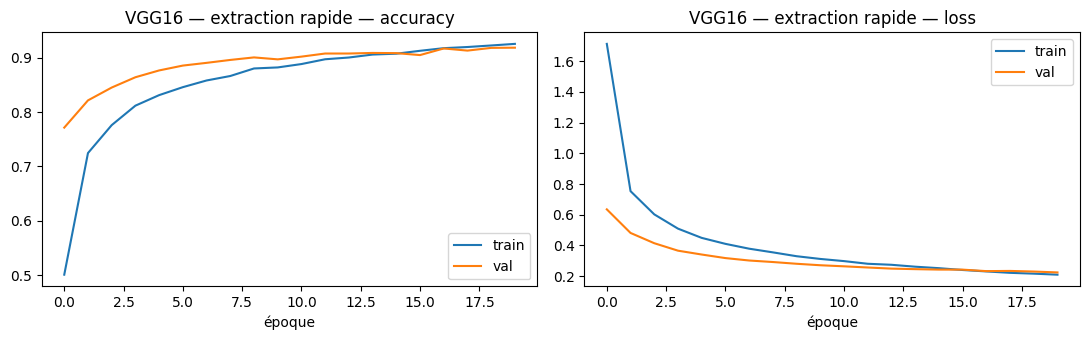

Test accuracy : 0.908  |  params entraînés : 133,384


In [ ]:
def build_head(input_shape, pool=True, name='tete'):
    """Tête de classification : [GAP] -> Dense(256, relu) -> Dropout(0.5) -> Dense(8, softmax)"""
    L = [keras.Input(shape=input_shape)]
    if pool:
        L.append(layers.GlobalAveragePooling2D())
    L += [layers.Dense(256, activation='relu'),
          layers.Dropout(0.5),
          layers.Dense(NUM_CLASSES, activation='softmax')]
    return keras.Sequential(L, name=name)

head = build_head(Xtr.shape[1:], pool=True, name='tete_vgg')
head.compile(optimizer=keras.optimizers.Adam(1e-4),
             loss='sparse_categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h_fast = head.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=20, batch_size=32, verbose=2)
t_fast = time.time() - t0 + t_extract
plot_history(h_fast, 'VGG16 — extraction rapide')
loss, acc = head.evaluate(Xte, yte, verbose=0)
results['VGG16 extraction rapide'] = (acc, head.count_params(), t_fast)
print(f"Test accuracy : {acc:.3f}  |  params entraînés : {head.count_params():,}")

> ❓ **Question 5.** Comparez la précision test et le nombre de paramètres entraînés avec le CNN from scratch. Comment expliquer un tel écart avec si peu de paramètres entraînés ?

✍️ *Votre réponse :*

| | CNN from scratch | VGG16 extraction rapide |
|---|---|---|
| Précision test | **[XX %]** | **[XX %]** |
| Paramètres entraînés | **[XX]** | **[XX]** *(≈ 133 000 : seulement la tête)* |

*(Recopiez les valeurs depuis le tableau `results` ou les sorties.)*

**Explication** (à adapter selon votre écart réel) : les 14,7 M de paramètres de VGG16 sont **gelés** et déjà entraînés sur 1,2 M d'images : ses filtres extraient des bords, textures et formes de façon robuste. La tête n'a plus qu'à **combiner** ces caractéristiques pour séparer les 8 classes, ce qui demande très peu de paramètres. Le CNN from scratch doit au contraire apprendre *tous* ses filtres à partir de poids aléatoires.

> ❓ **Question 6 (bonus).** Que se passe-t-il si on oublie `preprocess_input` ? Testez en remplaçant `pre_vgg` par `lambda x: x / 255.`

In [ ]:
# BONUS Q6 : extraction avec x/255 au lieu de preprocess_input (n'écrase pas les variables précédentes)
pre_255 = lambda x: x / 255.
Xtr_b, ytr_b = extract_features(conv_base, pre_255, train_ds)
Xva_b, yva_b = extract_features(conv_base, pre_255, val_ds)
Xte_b, yte_b = extract_features(conv_base, pre_255, test_ds)

head_b = build_head(Xtr_b.shape[1:], pool=True, name='tete_vgg_255')
head_b.compile(optimizer=keras.optimizers.Adam(1e-4),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])
head_b.fit(Xtr_b, ytr_b, validation_data=(Xva_b, yva_b), epochs=20, batch_size=32, verbose=0)
_, acc_b = head_b.evaluate(Xte_b, yte_b, verbose=0)
print(f"Test accuracy avec x/255 : {acc_b:.3f}   (avec preprocess_input : {results['VGG16 extraction rapide'][0]:.3f})")

del Xtr_b, Xva_b, Xte_b   # libère la RAM

Test accuracy avec x/255 : 0.841   (avec preprocess_input : 0.908)


### 3.3 — Base gelée **avec** augmentation (modèle de bout en bout)
L'extraction rapide ne permet pas l'augmentation (les caractéristiques sont figées). On construit donc un modèle complet : `augmentation → preprocess → VGG16 gelée → tête`.

In [ ]:
# 1) Gel de la base
conv_base.trainable = False

# 2) API fonctionnelle : augmentation -> preprocess -> VGG16 gelée -> tête
inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = pre_vgg(x)
x = conv_base(x, training=False)       # training=False : base en mode inférence
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

# 3) Modèle final
model_vgg = keras.Model(inputs, outputs, name='vgg16_transfer')
model_vgg.compile(optimizer=keras.optimizers.Adam(1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

n_train  = sum(np.prod(w.shape) for w in model_vgg.trainable_weights)
n_frozen = sum(np.prod(w.shape) for w in model_vgg.non_trainable_weights)
print(f"Entraînables : {n_train:,}  |  gelés : {n_frozen:,}")

Entraînables : 133,384  |  gelés : 14,714,688


Epoch 1/8
575/575 - 108s - 189ms/step - accuracy: 0.4666 - loss: 1.7198 - val_accuracy: 0.7536 - val_loss: 0.7049
Epoch 2/8
575/575 - 93s - 162ms/step - accuracy: 0.6741 - loss: 0.8806 - val_accuracy: 0.8132 - val_loss: 0.5321
Epoch 3/8
575/575 - 93s - 162ms/step - accuracy: 0.7382 - loss: 0.7017 - val_accuracy: 0.8300 - val_loss: 0.4627
Epoch 4/8
575/575 - 102s - 177ms/step - accuracy: 0.7695 - loss: 0.6051 - val_accuracy: 0.8407 - val_loss: 0.4195
Epoch 5/8
575/575 - 94s - 163ms/step - accuracy: 0.7930 - loss: 0.5476 - val_accuracy: 0.8589 - val_loss: 0.3841
Epoch 6/8
575/575 - 150s - 261ms/step - accuracy: 0.8081 - loss: 0.5118 - val_accuracy: 0.8582 - val_loss: 0.3788
Epoch 7/8
575/575 - 89s - 156ms/step - accuracy: 0.8203 - loss: 0.4711 - val_accuracy: 0.8686 - val_loss: 0.3539
Epoch 8/8
575/575 - 147s - 255ms/step - accuracy: 0.8318 - loss: 0.4485 - val_accuracy: 0.8779 - val_loss: 0.3445


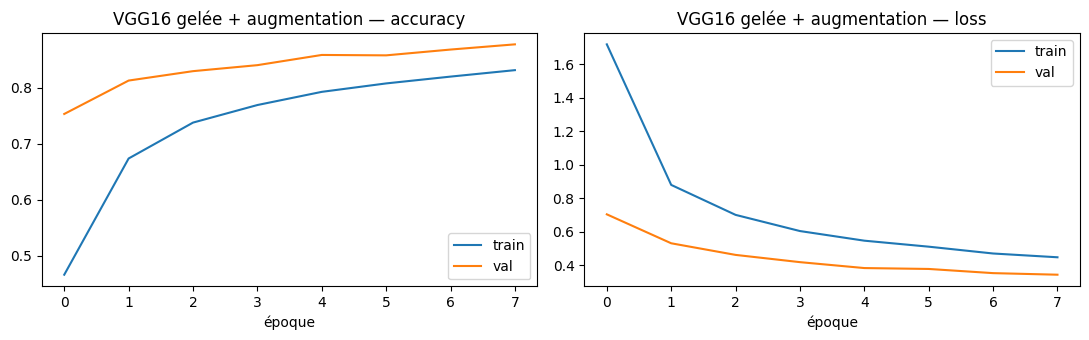

Test accuracy : 0.863  |  durée : 877 s


In [ ]:
EPOCHS_FROZEN = 8
t0 = time.time()
h_frozen = model_vgg.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=2)
t_frozen = time.time() - t0
plot_history(h_frozen, 'VGG16 gelée + augmentation')
loss, acc = model_vgg.evaluate(test_ds, verbose=0)
results['VGG16 gelée + augmentation'] = (acc, n_train, t_frozen)
print(f"Test accuracy : {acc:.3f}  |  durée : {t_frozen:.0f} s")

> ❓ **Question 7.** Pourquoi une époque est-elle beaucoup plus lente ici qu'en 3.2 alors qu'on entraîne le même nombre de paramètres ? Que gagne-t-on en contrepartie (regardez l'écart train/val) ?

✍️ *Votre réponse :*

**Lenteur** : en 3.2, les caractéristiques VGG16 étaient calculées **une seule fois** et stockées ; chaque époque n'entraînait que la petite tête sur des vecteurs déjà prêts. Ici, à **chaque époque et chaque batch**, les images subissent l'augmentation puis traversent **toute la base VGG16** (14,7 M de paramètres gelés, mais calculés en propagation avant). Les paramètres entraînés sont les mêmes (la tête), mais le coût de calcul est bien plus grand.

**Contrepartie** : comme chaque époque présente des variantes différentes des images, le modèle mémorise moins : l'écart train/val *(à vérifier sur vos courbes : durée par époque et écart entre les deux courbes)* est plus faible qu'en 3.2, et la généralisation est plus robuste.

## Partie 4 — Fine-tuning : dégeler le dernier bloc de VGG16
Les premiers blocs de VGG16 détectent des motifs **génériques** (bords, couleurs) utiles partout ; le **block5** encode des motifs plus **spécifiques** à ImageNet. On dégèle uniquement `block5_*` et on ré-entraîne avec un **learning rate très faible**.

⚠️ Règle d'or : on ne fait le fine-tuning **qu'après** avoir entraîné la tête (sinon les gradients aléatoires de la tête détruisent les poids pré-entraînés). C'est pourquoi cette partie vient après la 3.3.

In [ ]:
# On rend la base entraînable, puis on regèle tout sauf block5
conv_base.trainable = True
for layer in conv_base.layers:
    if not layer.name.startswith('block5'):
        layer.trainable = False

print([l.name for l in conv_base.layers if l.trainable])

# Re-compilation OBLIGATOIRE avec un learning rate très faible
model_vgg.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

n_train_ft = sum(np.prod(w.shape) for w in model_vgg.trainable_weights)
print(f"Paramètres entraînables après dégel : {n_train_ft:,}")

['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']
Paramètres entraînables après dégel : 7,212,808


Epoch 1/5
575/575 - 102s - 178ms/step - accuracy: 0.8834 - loss: 0.3176 - val_accuracy: 0.9239 - val_loss: 0.2138
Epoch 2/5
575/575 - 101s - 176ms/step - accuracy: 0.9244 - loss: 0.2171 - val_accuracy: 0.9375 - val_loss: 0.1771
Epoch 3/5
575/575 - 102s - 177ms/step - accuracy: 0.9396 - loss: 0.1788 - val_accuracy: 0.9371 - val_loss: 0.1886
Epoch 4/5
575/575 - 102s - 178ms/step - accuracy: 0.9485 - loss: 0.1562 - val_accuracy: 0.9471 - val_loss: 0.1529
Epoch 5/5
575/575 - 111s - 194ms/step - accuracy: 0.9516 - loss: 0.1387 - val_accuracy: 0.9475 - val_loss: 0.1511


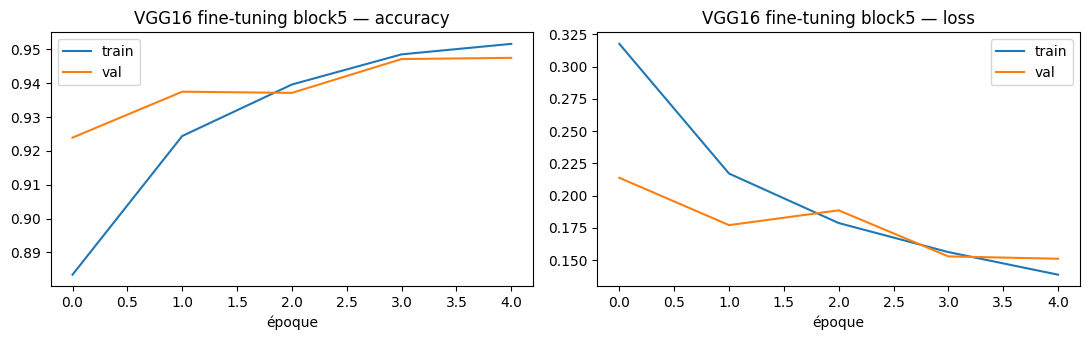

Test accuracy : 0.944  |  durée : 519 s


In [ ]:
EPOCHS_FT = 5
t0 = time.time()
h_ft = model_vgg.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, verbose=2)
t_ft = time.time() - t0

plot_history(h_ft, 'VGG16 fine-tuning block5')
loss, acc = model_vgg.evaluate(test_ds, verbose=0)
results['VGG16 fine-tuning'] = (acc, n_train_ft, t_frozen + t_ft)
print(f"Test accuracy : {acc:.3f}  |  durée : {t_ft:.0f} s")

> ❓ **Question 8.** Combien de paramètres sont entraînables après dégel du block5 ? Pourquoi divise-t-on le learning rate par 10 ? Que risquerait-on en dégelant **toute** la base avec cette quantité d'images ?

✍️ *Votre réponse :*

**Paramètres entraînables** : block5 = 3 couches de convolution 512→512 en 3×3, soit 3 × 2 359 808 = **7 079 424** paramètres, auxquels s'ajoute la tête : 512×256+256 = 131 328 (Dense 256) et 256×8+8 = 2 056 (Dense 8), soit 133 384. Total attendu : **7 212 808** *(à comparer avec la valeur affichée par votre cellule ; avant dégel on avait 133 384 paramètres entraînables)*.

**Pourquoi diviser le learning rate par 10 ?** (1e-5 au lieu de 1e-4) La base contient déjà des poids de bonne qualité. Un learning rate trop grand modifierait brutalement ces filtres (« oubli catastrophique ») ; un learning rate faible permet de les **ajuster doucement** à nos images OCT.

**Risque en dégelant toute la base** : 14,7 M de paramètres à ajuster, y compris les premiers blocs qui détectent des motifs génériques et utiles. Le coût de calcul augmente fortement, et le modèle risque de sur-apprendre et de dégrader ces filtres génériques.

## Partie 5 — ResNet50 : plus profond, mais plus léger
ResNet50 (50 couches) utilise des **connexions résiduelles** (*skip connections*) : chaque bloc apprend une correction `F(x)` ajoutée à son entrée → `y = F(x) + x`. Le gradient circule directement et on peut empiler beaucoup plus de couches que VGG.

In [ ]:
# Base ResNet50 ImageNet sans la tête + sa fonction de prétraitement propre
pre_resnet = keras.applications.resnet50.preprocess_input
resnet_base = keras.applications.ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=IMG_SIZE + (3,)
)

print("Couches :", len(resnet_base.layers), "| paramètres :", f"{resnet_base.count_params():,}")
print("Sortie :", resnet_base.output_shape)

# Repérer une connexion résiduelle (opération d'addition 'add')
print([l.name for l in resnet_base.layers if l.name.startswith('conv2_block1') and 'add' in l.name])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Couches : 175 | paramètres : 23,587,712
Sortie : (None, 7, 7, 2048)
['conv2_block1_add']


Rtr : (18400, 2048) | extraction : 294 s
Epoch 1/20
575/575 - 5s - 9ms/step - accuracy: 0.6848 - loss: 0.8452 - val_accuracy: 0.8311 - val_loss: 0.4552
Epoch 2/20
575/575 - 2s - 3ms/step - accuracy: 0.8183 - loss: 0.4899 - val_accuracy: 0.8557 - val_loss: 0.3779
Epoch 3/20
575/575 - 2s - 3ms/step - accuracy: 0.8505 - loss: 0.4052 - val_accuracy: 0.8779 - val_loss: 0.3318
Epoch 4/20
575/575 - 2s - 3ms/step - accuracy: 0.8697 - loss: 0.3561 - val_accuracy: 0.8793 - val_loss: 0.3167
Epoch 5/20
575/575 - 2s - 3ms/step - accuracy: 0.8855 - loss: 0.3204 - val_accuracy: 0.8907 - val_loss: 0.2925
Epoch 6/20
575/575 - 2s - 4ms/step - accuracy: 0.8916 - loss: 0.2985 - val_accuracy: 0.8932 - val_loss: 0.2802
Epoch 7/20
575/575 - 2s - 4ms/step - accuracy: 0.8990 - loss: 0.2784 - val_accuracy: 0.8932 - val_loss: 0.2757
Epoch 8/20
575/575 - 2s - 3ms/step - accuracy: 0.9063 - loss: 0.2621 - val_accuracy: 0.8946 - val_loss: 0.2681
Epoch 9/20
575/575 - 2s - 3ms/step - accuracy: 0.9107 - loss: 0.2444 - 

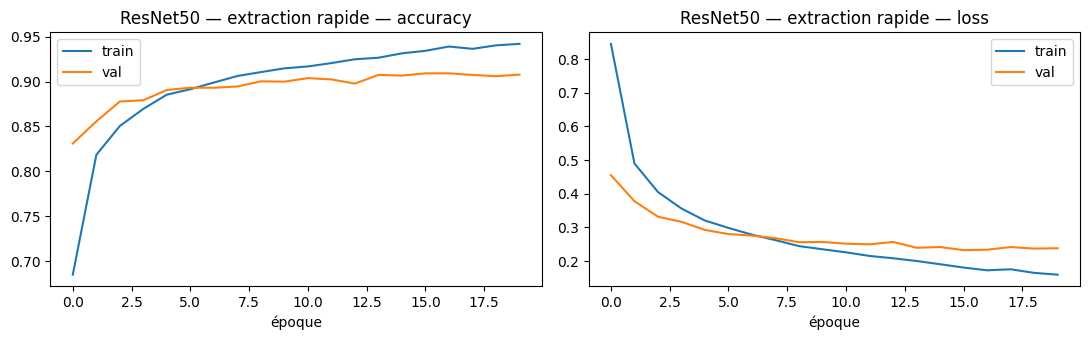

Test accuracy : 0.915  |  params entraînés : 526,600


In [ ]:
# Même chose qu'en 3.2 avec resnet_base et pre_resnet.
# Sortie ResNet50 = 7x7x2048 : stockée telle quelle, le train ferait ~7 Go de RAM.
# On applique donc le GlobalAveragePooling directement à l'extraction (pool=True) -> vecteurs de 2048.
t0 = time.time()
Rtr, rtr = extract_features(resnet_base, pre_resnet, train_ds, pool=True)
Rva, rva = extract_features(resnet_base, pre_resnet, val_ds,   pool=True)
Rte, rte = extract_features(resnet_base, pre_resnet, test_ds,  pool=True)
t_extract_r = time.time() - t0
print("Rtr :", Rtr.shape, f"| extraction : {t_extract_r:.0f} s")

head_r = build_head(Rtr.shape[1:], pool=False, name='tete_resnet')   # déjà poolé
head_r.compile(optimizer=keras.optimizers.Adam(1e-4),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h_r = head_r.fit(Rtr, rtr, validation_data=(Rva, rva), epochs=20, batch_size=32, verbose=2)
t_r = time.time() - t0 + t_extract_r
plot_history(h_r, 'ResNet50 — extraction rapide')
loss, acc = head_r.evaluate(Rte, rte, verbose=0)
results['ResNet50 extraction rapide'] = (acc, head_r.count_params(), t_r)
print(f"Test accuracy : {acc:.3f}  |  params entraînés : {head_r.count_params():,}")

> ❓ **Question 10.** Comparez VGG16 et ResNet50 : nombre de couches, nombre de paramètres de la base, taille de la sortie (canaux), temps d'extraction, précision. Lequel choisiriez-vous pour une application mobile ?

✍️ *Votre réponse :*

| | VGG16 | ResNet50 |
|---|---|---|
| Couches de la base | 19 *(entrée + 13 conv + 5 pooling)* | **[XXX]** *(sortie de `len(resnet_base.layers)`)* |
| Paramètres de la base | 14 714 688 | **[XX]** *(≈ 23,6 M, voir la sortie)* |
| Canaux en sortie | 512 | 2048 |
| Temps d'extraction + entraînement | **[XX s]** | **[XX s]** |
| Précision test | **[XX %]** | **[XX %]** |

*(Recopiez les valeurs depuis le tableau `results` et les sorties.)*

**Choix pour une application mobile** : ni l'un ni l'autre n'est idéal (modèles lourds). On préférerait une architecture conçue pour la légèreté comme **MobileNetV2/V3** ou **EfficientNet-B0**. Entre les deux, ResNet50 est plus profond mais utilise des connexions résiduelles et un pooling global (pas de grosses couches denses), tandis que VGG16 est plus gourmand en calcul.

## Partie 6 — Bilan et analyse des erreurs

,Modèle,Accuracy test,Params entraînés,Durée (s)
0,VGG16 extraction rapide,90.8 %,"133,384",264
1,VGG16 gelée + augmentation,86.3 %,"133,384",877
2,VGG16 fine-tuning,94.4 %,"7,212,808",1396
3,ResNet50 extraction rapide,91.5 %,"526,600",338


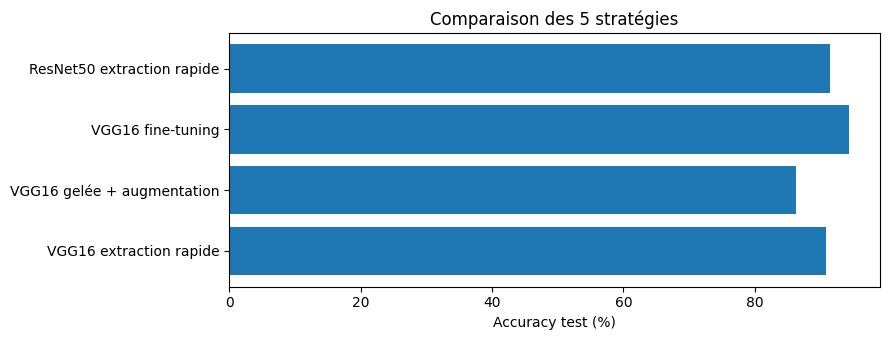

In [ ]:
df = pd.DataFrame([(k, f"{v[0]*100:.1f} %", f"{int(v[1]):,}", f"{v[2]:.0f}") for k, v in results.items()],
                  columns=['Modèle', 'Accuracy test', 'Params entraînés', 'Durée (s)'])
display(df)

# Graphique comparatif
plt.figure(figsize=(9, 3.5))
plt.barh(list(results.keys()), [v[0] * 100 for v in results.values()])
plt.xlabel('Accuracy test (%)'); plt.title('Comparaison des 5 stratégies')
plt.tight_layout(); plt.show()

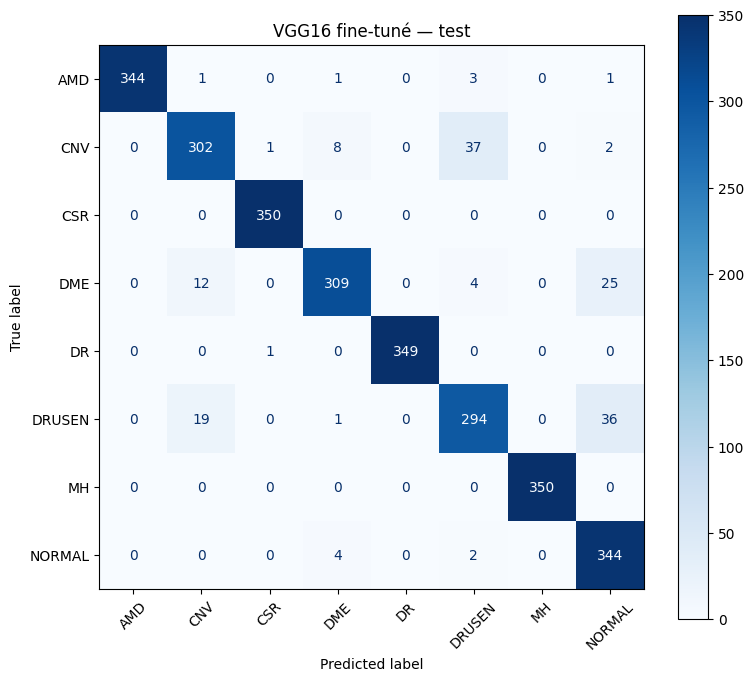

              precision    recall  f1-score   support

         AMD      1.000     0.983     0.991       350
         CNV      0.904     0.863     0.883       350
         CSR      0.994     1.000     0.997       350
         DME      0.957     0.883     0.918       350
          DR      1.000     0.997     0.999       350
      DRUSEN      0.865     0.840     0.852       350
          MH      1.000     1.000     1.000       350
      NORMAL      0.843     0.983     0.908       350

    accuracy                          0.944      2800
   macro avg      0.945     0.944     0.944      2800
weighted avg      0.945     0.944     0.944      2800

158 erreurs sur 2800 images


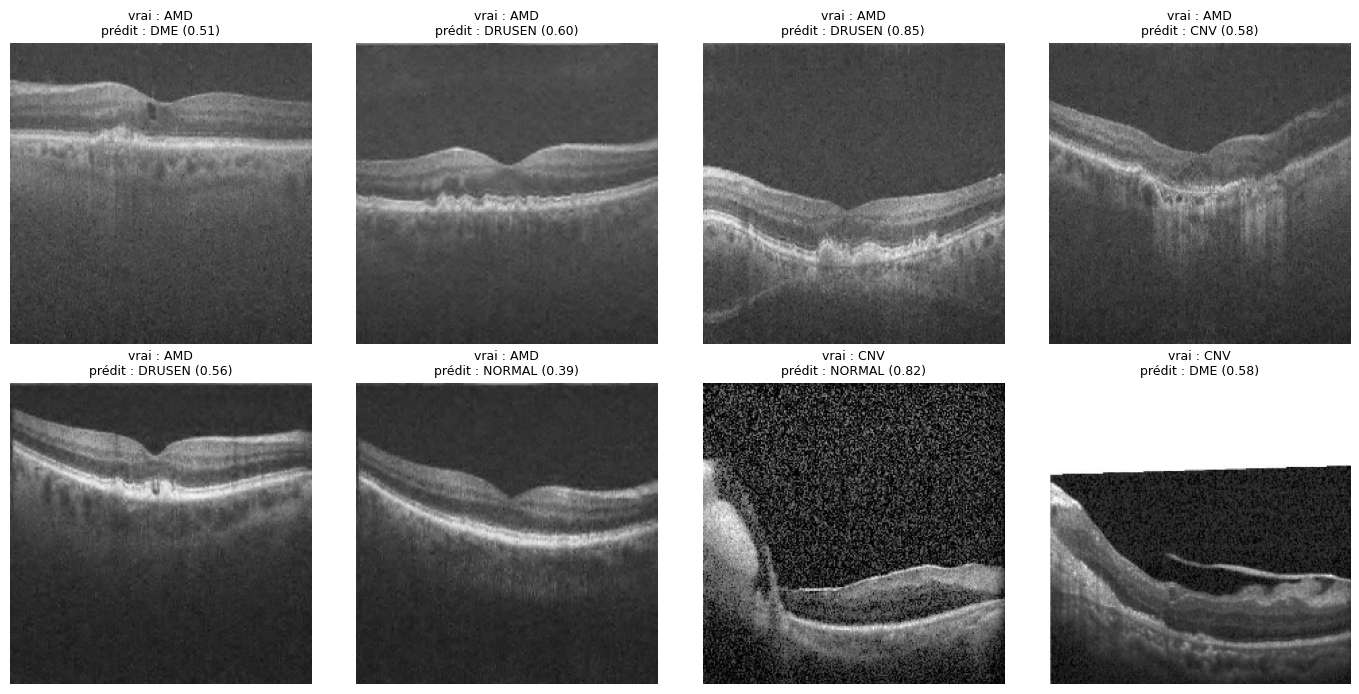

In [ ]:
# Analyse des erreurs du meilleur modèle (VGG16 fine-tuné) sur le jeu de TEST
# (test_ds est en shuffle=False : prédictions et étiquettes restent alignées)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

x_all, y_all = [], []
for x, y in test_ds:
    x_all.append(x.numpy().astype('uint8')); y_all.append(y.numpy())
x_all = np.concatenate(x_all)
y_all = np.concatenate(y_all)

proba = model_vgg.predict(test_ds, verbose=0)
pred = proba.argmax(axis=1)

# Matrice de confusion 8x8
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_all, pred), display_labels=class_names).plot(
    cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('VGG16 fine-tuné — test'); plt.tight_layout(); plt.show()

# Précision / rappel (sensibilité) par classe
print(classification_report(y_all, pred, target_names=class_names, digits=3))

# Premières erreurs
err = np.where(pred != y_all)[0]
print(f"{len(err)} erreurs sur {len(y_all)} images")

plt.figure(figsize=(14, 7))
for i, k in enumerate(err[:8]):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_all[k]); plt.axis('off')
    plt.title(f"vrai : {class_names[y_all[k]]}\nprédit : {class_names[pred[k]]} ({proba[k].max():.2f})", fontsize=9)
plt.tight_layout(); plt.show()